# Outliar Detection

In [45]:
import pandas as pd 
import numpy as np

df = pd.read_csv("./data/03_Handling_Missing_Values.csv")

In [46]:
df.shape

(57130, 29)

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

if 's_no_of_scheme' in df.columns:
    df.drop(columns=['s_no_of_scheme'], inplace=True)
    print("deleted successfully.")
else:
    print("column not found.")

data = df

# Preserve original data and create a working copy
df_original = data.copy(deep=True)
df_clean = data.copy(deep=True)

# Identify column types
numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df_clean.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

print("Dataset shape:", df_clean.shape)
print("Numeric columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))
print("\nNumeric columns:")
print(numeric_cols)
print("\nCategorical columns:")
print(categorical_cols)


deleted successfully.
Dataset shape: (57130, 28)
Numeric columns: 9
Categorical columns: 19

Numeric columns:
['latitude', 'longitude', 'total_owners_holding', 'scheme_depth', 'scheme_diameter', 'nearest_scheme_distance', 'construction_cost', 'horse_power_of_lifting_device', 'culturable_command_area']

Categorical columns:
['district_name', 'block_tehsil_name', 'village_name', 'scheme_type', 'ownership', 'social_status', 'gender', 'commissioning_year', 'scheme_status', 'water_distribution_method', 'lifting_device_type', 'energy_source', 'located_in_command_area', 'only_recharge_ground_water', 'under_utilised_selection', 'drinking_water_purpose', 'captured_in_previous_census', 'well_type', 'finance_source']


# 1. Univariate Outlier Detection

## 1.1 Visual Methods

### Boxplot

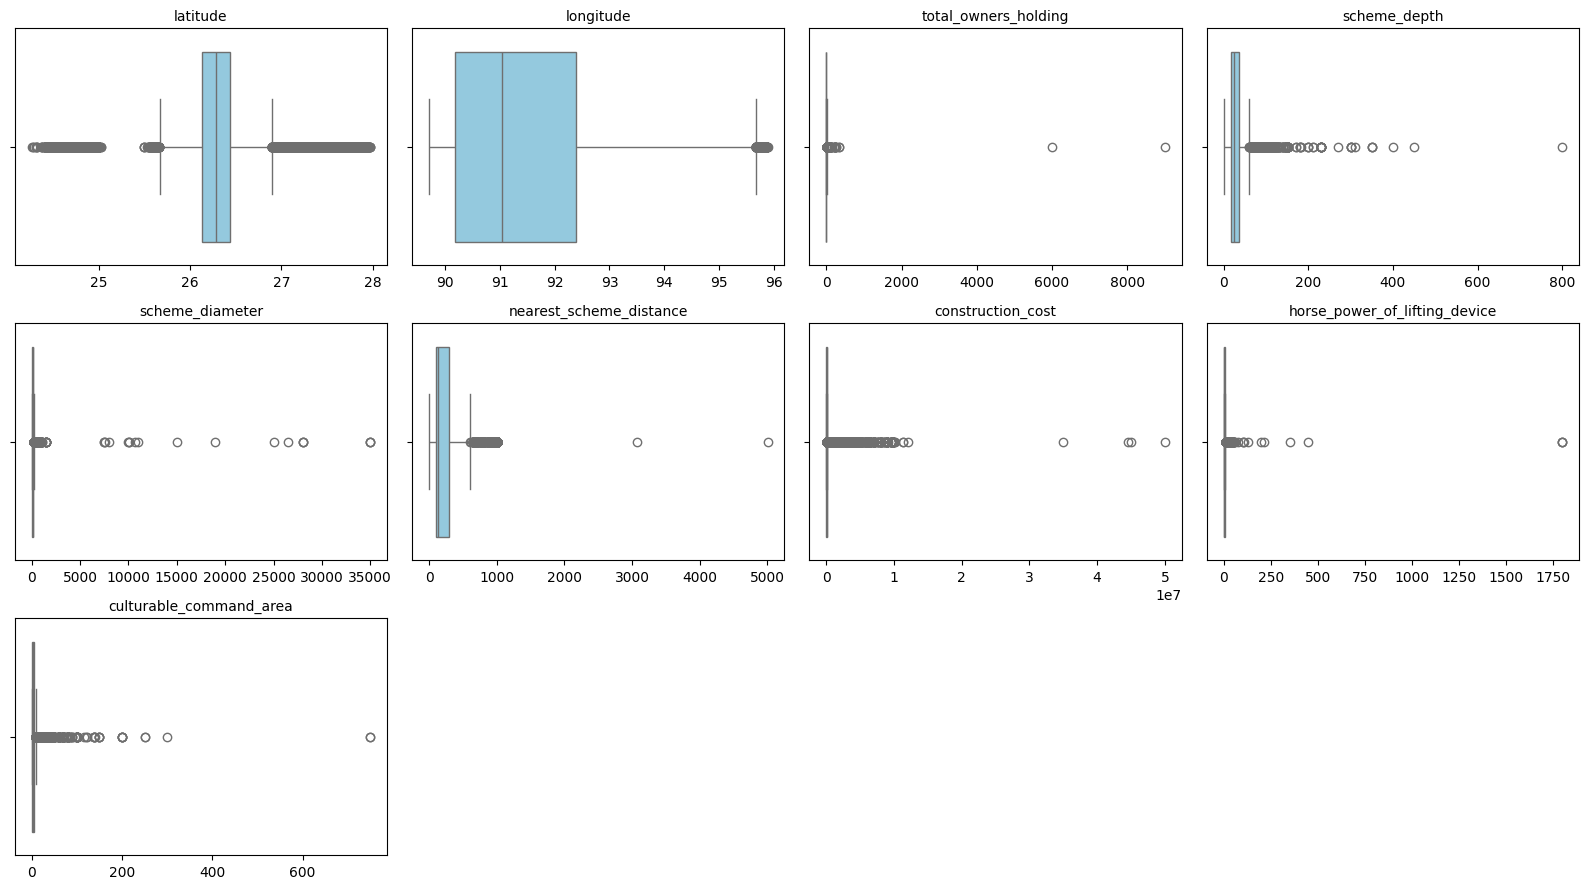

In [4]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = df_clean.select_dtypes(include="number").columns

ncols = 4
nrows = math.ceil(len(numeric_cols) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(x=df_clean[col], ax=ax, color="skyblue")
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")

for ax in axes[len(numeric_cols):]:
    ax.remove()

plt.tight_layout()
plt.show()

### Histogram

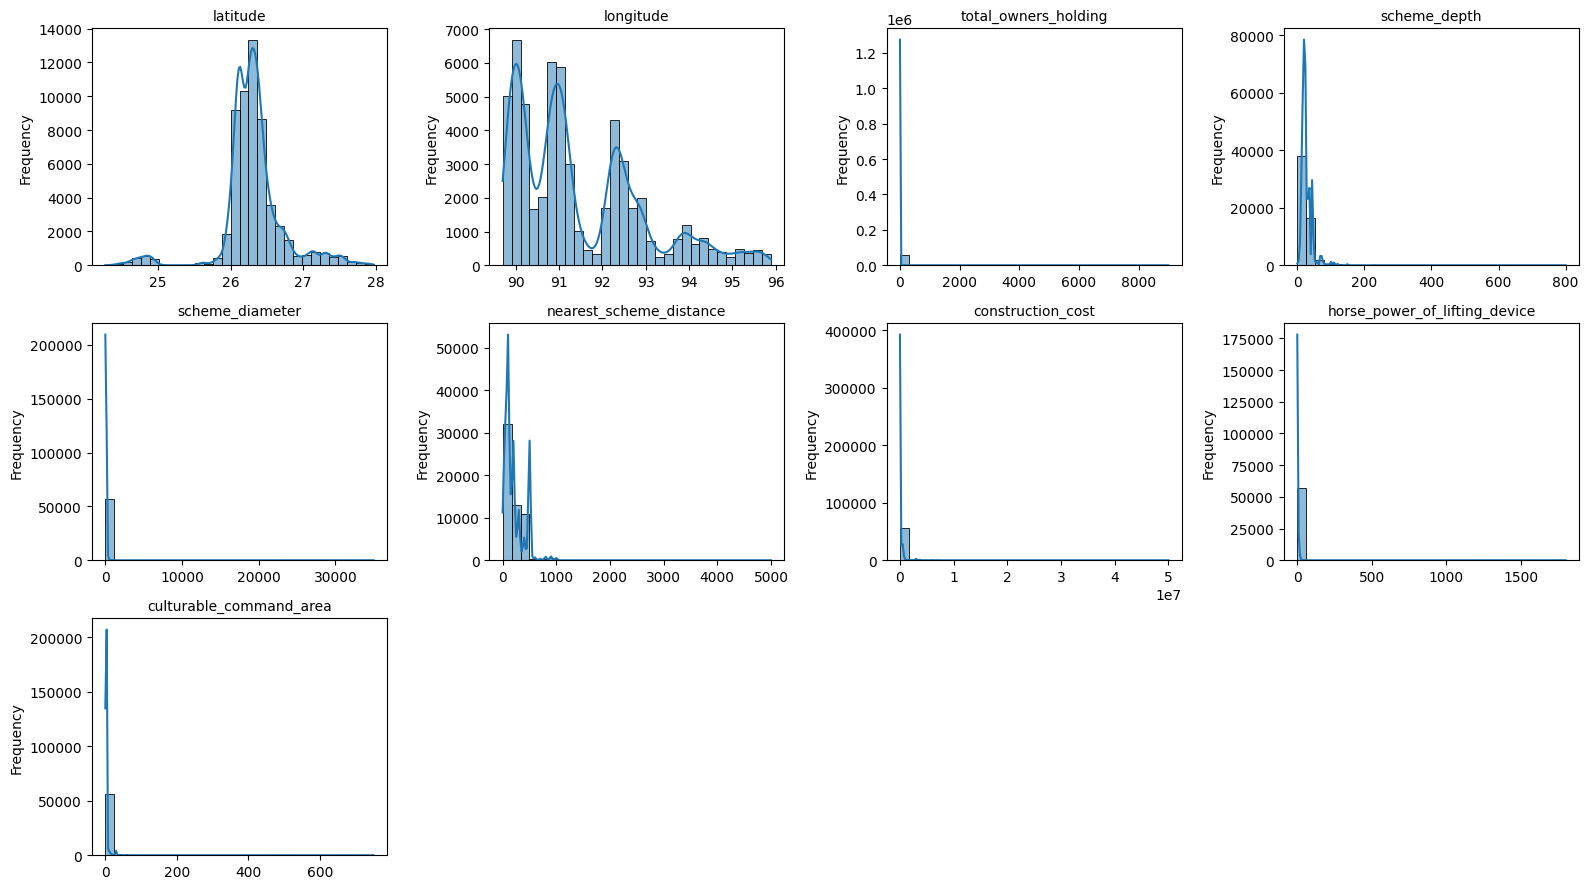

In [5]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

# Select all numerical columns
numeric_cols = df_clean.select_dtypes(include="number").columns

# Configure subplot layout
ncols = 4
nrows = math.ceil(len(numeric_cols) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(16, 3 * nrows)
)

axes = axes.flatten()

# Plot histograms with KDE
for ax, col in zip(axes, numeric_cols):
    sns.histplot(
        df_clean[col].dropna(),
        bins=30,
        kde=True,
        ax=ax
    )

    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("Frequency")

# Remove unused subplots
for ax in axes[len(numeric_cols):]:
    ax.remove()

plt.tight_layout()
plt.show()

## 1.2 Statistical Methods

### IQR

In [6]:
# Calculate Q1, Q3 and IQR
Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)

IQR = Q3 - Q1

# Calculate lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Calculate outlier summary without adding columns to df
outlier_counts = {}

for col in numeric_cols:
    outliers = (
        (df[col] < lower_bound[col]) |
        (df[col] > upper_bound[col])
    )

    outlier_counts[col] = {
        "Lower Bound": lower_bound[col],
        "Upper Bound": upper_bound[col],
        "Outlier Count": outliers.sum(),
        "Outlier Percentage": outliers.mean() * 100
    }

# Display summary
iqr_summary = pd.DataFrame.from_dict(
    outlier_counts,
    orient='index'
)

display(
    iqr_summary.sort_values(
        by="Outlier Count",
        ascending=False
    ).round(2)
)

,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
construction_cost,-27500.00,72500.00,11806,20.67
latitude,25.67,26.90,5725,10.02
scheme_depth,-7.50,60.50,2223,3.89
culturable_command_area,-3.50,8.50,1992,3.49
scheme_diameter,-112.50,227.50,1112,1.95
horse_power_of_lifting_device,-2.50,9.50,935,1.64
nearest_scheme_distance,-200.00,600.00,868,1.52
total_owners_holding,-3.00,5.00,851,1.49
longitude,86.89,95.67,354,0.62


#### Treatement 

In [7]:
# s_no_of_scheme is serail numberabs
# scheme_depth, scheme_diameter we will lwave them alone for now
# longitude and latitude are also correct

In [8]:
# we will leave culturable_command_area alone
value_summary = df['culturable_command_area'].value_counts(
    dropna=False
).sort_index().to_frame('Count')

value_summary['Percentage'] = (
    value_summary['Count'] / len(df) * 100
).round(2)

display(value_summary)

,Count,Percentage
culturable_command_area,,
0.000,1755,3.07
0.001,3,0.01
0.010,1,0.00
0.020,2,0.00
0.026,1,0.00
...,...,...
150.000,4,0.01
200.000,5,0.01
250.000,2,0.00


##### working on horse_power_of_lifting_device

### Z-Score

In [9]:
import pandas as pd
import numpy as np
from scipy.stats import zscore

# Calculate Z-Scores
z_scores = pd.DataFrame(
    zscore(df[numeric_cols], nan_policy="omit"),
    columns=numeric_cols,
    index=df.index
)

# Identify outliers (|Z-Score| > 3)
z_outliers = z_scores.abs() > 3

# Create summary
outlier_counts = z_outliers.sum()

zscore_summary = pd.DataFrame({
    "Outlier Count": outlier_counts,
    "Outlier Percentage": (
        outlier_counts / len(df) * 100
    )
})

# Display summary
display(zscore_summary.sort_values(
    by="Outlier Count",
    ascending=False
))

,Outlier Count,Outlier Percentage
latitude,2071,3.625066
scheme_depth,964,1.687380
construction_cost,897,1.570103
nearest_scheme_distance,744,1.302293
culturable_command_area,676,1.183266
longitude,77,0.134780
scheme_diameter,27,0.047261
horse_power_of_lifting_device,23,0.040259
total_owners_holding,14,0.024506


### Outliers using IQR and Z-Score

In [10]:
import pandas as pd
import numpy as np
from scipy.stats import zscore

# Calculate IQR bounds
Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify IQR outliers
iqr_outliers = (
    (df[numeric_cols] < lower_bound) |
    (df[numeric_cols] > upper_bound)
)

# Calculate Z-Scores
z_scores = pd.DataFrame(
    zscore(df[numeric_cols], nan_policy="omit"),
    columns=numeric_cols,
    index=df.index
)

# Identify Z-Score outliers
z_outliers = z_scores.abs() > 3

# Combine both methods (AND condition)
combined_outliers = iqr_outliers & z_outliers


# Create summary
combined_summary = pd.DataFrame({
    "IQR Outliers": iqr_outliers.sum(),
    "Z-Score Outliers": z_outliers.sum(),
    "Detected by Both": combined_outliers.sum()
})

display(combined_summary)

,IQR Outliers,Z-Score Outliers,Detected by Both
latitude,5725,2071,2071
longitude,354,77,77
total_owners_holding,851,14,14
scheme_depth,2223,964,964
scheme_diameter,1112,27,27
nearest_scheme_distance,868,744,744
construction_cost,11806,897,897
horse_power_of_lifting_device,935,23,23
culturable_command_area,1992,676,676


#### Treatement

##### Working on construction cost

In [11]:
# Drop records where construction_cost is below 10
df = df[df['construction_cost'] >= 10].copy()

print("Remaining records:", len(df))

Remaining records: 55993


##### Working on nearest_scheme_distance

In [12]:
# Identify records flagged by both IQR and Z-score
common_outliers = combined_outliers['nearest_scheme_distance']

# Inspect outlier records
outlier_records = df.loc[common_outliers, [
    'nearest_scheme_distance',
    'latitude',
    'longitude',
    'district_name',
    'village_name'
]].copy()

print("Outlier records:", len(outlier_records))
print("\nOutlier distance summary:")
print(outlier_records['nearest_scheme_distance'].describe())

display(
    outlier_records.sort_values(
        'nearest_scheme_distance',
        ascending=False
    ).head(30)
)

# Remove records flagged by both methods
df = df.loc[~common_outliers].copy()

print("\nRemaining records:", len(df))
print("\nUpdated distance summary:")
print(df['nearest_scheme_distance'].describe())

Outlier records: 708

Outlier distance summary:
count     708.000000
mean      894.128531
std       190.574347
min       750.000000
25%       800.000000
50%       900.000000
75%       900.000000
max      5001.000000
Name: nearest_scheme_distance, dtype: float64


,nearest_scheme_distance,latitude,longitude,district_name,village_name
28786,5001.0,24.890162,92.693230,Cachar,Chandpur Pt IV
40837,3070.0,26.253370,91.157152,Barpeta,Sarudia
10321,1001.0,26.276713,92.119710,Marigaon,Garakhia Dhap
1475,999.0,26.618236,93.586587,Golaghat,Koilakhat
31533,999.0,26.058537,93.776497,Karbi Anglong,"Tal Balijan 1,2"
34221,999.0,27.105880,94.393955,Lakhimpur,Aken Dighali
54580,999.0,24.467141,92.471187,Karimganj,Veterbond
33864,999.0,26.105434,92.667257,Nagaon,Uppar Kahunda
33368,999.0,26.049215,90.725973,Goalpara,Dhaigaon Damas
33360,999.0,26.042516,90.719153,Goalpara,Dhaigaon Damas



Remaining records: 55285

Updated distance summary:
count    55285.000000
mean       193.390714
std        159.448127
min          0.010000
25%         90.000000
50%        120.000000
75%        300.000000
max        727.000000
Name: nearest_scheme_distance, dtype: float64


##### Working on scheme_diameter

In [13]:
col = 'scheme_diameter'

print("Total records:", len(df))
print("Missing values:", df[col].isna().sum())
print("Zero values:", (df[col] == 0).sum())
print("Negative values:", (df[col] < 0).sum())
print("Unique values:", df[col].nunique())

display(df[col].describe().to_frame().round(2))

Total records: 55285
Missing values: 0
Zero values: 0
Negative values: 0
Unique values: 287


,scheme_diameter
count,55285.00
mean,84.38
std,395.84
min,0.01
25%,22.00
50%,80.00
75%,100.00
max,35000.00


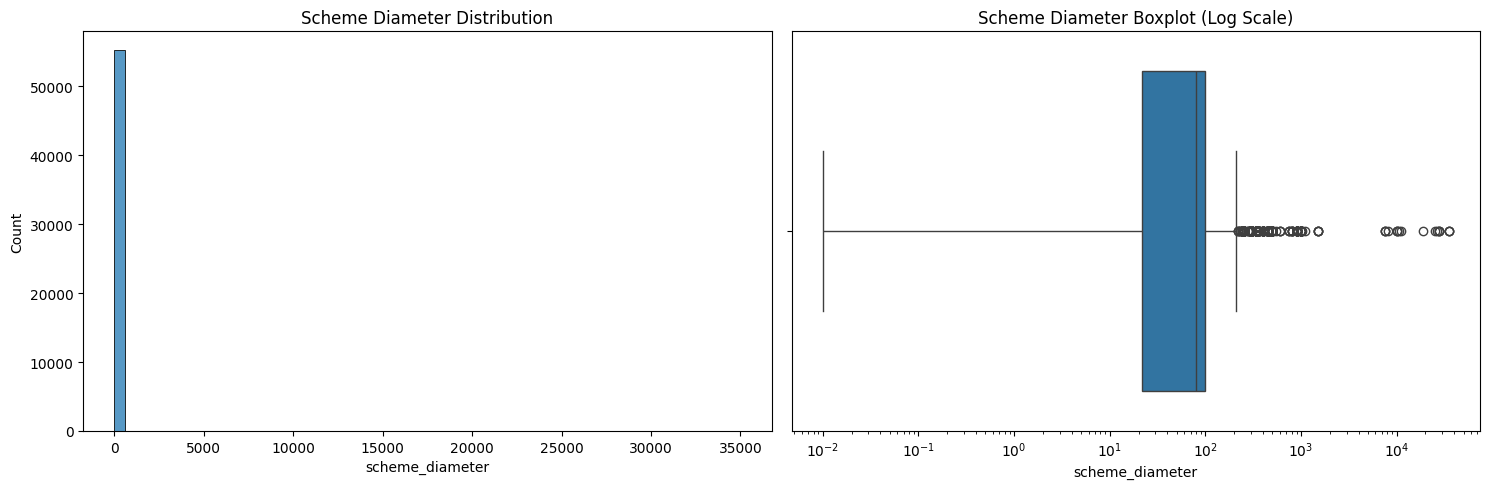

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(df[col], bins=60, ax=axes[0])
axes[0].set_title('Scheme Diameter Distribution')

sns.boxplot(x=df[col], ax=axes[1])
axes[1].set_xscale('log')
axes[1].set_title('Scheme Diameter Boxplot (Log Scale)')

plt.tight_layout()
plt.show()

In [15]:
col = 'scheme_diameter'

conversion_preview = df.loc[
    df[col].gt(0) & df[col].lt(10),
    [col]
].copy()

conversion_preview['Proposed_Diameter_mm'] = np.where(
    conversion_preview[col] < 1,
    conversion_preview[col] * 1000,
    conversion_preview[col] * 10
)

display(conversion_preview.head(30))

,scheme_diameter,Proposed_Diameter_mm
41,0.15,150.0
42,0.15,150.0
43,0.15,150.0
47,0.45,450.0
51,0.25,250.0
55,0.45,450.0
56,0.15,150.0
57,0.15,150.0
58,0.15,150.0
59,0.15,150.0


In [16]:
# Count records to be removed
print("Records to drop:", (df['scheme_diameter'] > 1000).sum())

# Drop records
df = df[df['scheme_diameter'] <= 1000].copy()

# Check updated range
print(df['scheme_diameter'].describe())
print("Remaining records:", len(df))

Records to drop: 27
count    55258.000000
mean        78.038827
std         63.125407
min          0.010000
25%         20.625000
50%         80.000000
75%        100.000000
max       1000.000000
Name: scheme_diameter, dtype: float64
Remaining records: 55258


In [17]:
df['scheme_diameter'].describe()

count    55258.000000
mean        78.038827
std         63.125407
min          0.010000
25%         20.625000
50%         80.000000
75%        100.000000
max       1000.000000
Name: scheme_diameter, dtype: float64

##### Working on horse_power_of_lifting_device

In [18]:
col = 'horse_power_of_lifting_device'

# Filter records flagged by both methods
hp_both_outliers = df.loc[
    combined_outliers[col],
    [
        col,
        'energy_source',
        'lifting_device_type',
        'scheme_type',
        'ownership'
    ]
].copy()

# Display in descending order of horsepower
display(
    hp_both_outliers.sort_values(
        by=col,
        ascending=False
    )
)

print("Total outliers detected by both:", len(hp_both_outliers))
print("Unique horsepower values:", hp_both_outliers[col].nunique())

,horse_power_of_lifting_device,energy_source,lifting_device_type,scheme_type,ownership
1442,1800.0,Solar,Centrifugal Pump,Tube well,Owned by Group of farmers
1654,1800.0,Solar,Centrifugal Pump,Tube well,Others
31144,1800.0,Solar,Centrifugal Pump,Tube well,Owned by individual farmer
54220,450.0,Solar,Submersible pump,Tube well,Owned by individual farmer
51769,350.0,Solar,Submersible pump,Tube well,Govt. Owned
19267,215.0,Solar,Centrifugal Pump,Tube well,Owned by individual farmer
28351,200.0,Solar,Submersible pump,Tube well,Govt. Owned
4655,130.0,Electric,Turbine/Jet pump,Tube well,Owned by Group of farmers
49359,106.0,Diesel,Turbine/Jet pump,Tube well,Owned by individual farmer
34269,105.0,Electric,Turbine/Jet pump,Tube well,Owned by individual farmer


Total outliers detected by both: 22
Unique horsepower values: 15


In [19]:
display(
    df.groupby('energy_source')['horse_power_of_lifting_device']
    .agg(['count', 'nunique', 'min', 'median', 'mean', 'max'])
    .round(2)
)

,count,nunique,min,median,mean,max
energy_source,,,,,,
Diesel,27174,47,0.0,5.0,4.54,106.0
Electric,17799,57,0.0,2.0,3.21,130.0
Manual/animal,1091,1,0.0,0.0,0.00,0.0
Natural,19,1,0.0,0.0,0.00,0.0
Not applicable,666,1,0.0,0.0,0.00,0.0
Others,680,18,0.0,5.0,4.08,25.0
Solar,7807,41,0.0,3.0,4.23,1800.0
Wind Mills,22,5,1.5,3.0,3.30,7.5


In [20]:
electric_records = df[
    df['energy_source'].str.lower().eq('electric')
]

display(
    electric_records[
        [
            'horse_power_of_lifting_device',
            'energy_source',
            'lifting_device_type',
            'scheme_type',
            'ownership'
        ]
    ].sort_values(
        'horse_power_of_lifting_device',
        ascending=False
    ).head(50)
)

,horse_power_of_lifting_device,energy_source,lifting_device_type,scheme_type,ownership
4655,130.0,Electric,Turbine/Jet pump,Tube well,Owned by Group of farmers
34269,105.0,Electric,Turbine/Jet pump,Tube well,Owned by individual farmer
30925,100.0,Electric,Submersible pump,Tube well,Owned by individual farmer
33547,50.0,Electric,Submersible pump,Tube well,Co-Operative Owned
48899,40.0,Electric,Submersible pump,Tube well,Govt. Owned
18782,40.0,Electric,Centrifugal Pump,Tube well,Others
4167,40.0,Electric,Centrifugal Pump,Tube well,Govt. Owned
46009,40.0,Electric,Submersible pump,Tube well,Govt. Owned
33764,40.0,Electric,Centrifugal Pump,Tube well,Govt. Owned
17428,40.0,Electric,Submersible pump,Tube well,Govt. Owned


In [21]:
col = 'horse_power_of_lifting_device'

pump_summary = df.groupby(
    ['energy_source', 'lifting_device_type'],
    dropna=False
)[col].agg(
    Total_Records='count',
    Unique_Values='nunique',
    Minimum='min',
    Median='median',
    Mean='mean',
    Maximum='max'
).round(2)

display(
    pump_summary.sort_values(
        by='Maximum',
        ascending=False
    )
)

Total_Records  Unique_Values  Minimum  \
energy_source  lifting_device_type                                          
Solar          Centrifugal Pump              2883             19     1.00   
               Submersible pump              4307             36     0.00   
Electric       Turbine/Jet pump               597             17     1.00   
Diesel         Turbine/Jet pump               926             20     0.15   
Electric       Submersible pump              4725             37     0.00   
Diesel         Centrifugal Pump             22065             33     0.00   
               Submersible pump              1233             21     0.15   
Electric       Centrifugal Pump             11313             36     0.00   
Diesel         Others                        2950             18     1.00   
Electric       Others                        1164             14     0.08   
Solar          Turbine/Jet pump               202             13     1.50   
               Others                         415             15     1.50   
Others         Others                         170             10     0.00   
               Centrifugal Pump               341             12     0.00   
               Submersible pump               125              9     0.00   
Wind Mills     Submersible pump                 8              4     2.00   
               Centrifugal Pump                12              3     1.50   
Others         Turbine/Jet pump                44              6     1.00   
Wind Mills     Others                           1              1     3.00   
               Turbine/Jet pump                 1              1     3.00   
Natural        Others                          19              1     0.00   
Not applicable Not applicable                 666              1     0.00   
Manual/animal  Manual/animal                 1091              1     0.00   

                                    Median  Mean  Maximum  
energy_source  lifting_device_type                         
Solar          Centrifugal Pump        2.0  4.36   1800.0  
               Submersible pump        3.0  4.25    450.0  
Electric       Turbine/Jet pump        3.0  4.11    130.0  
Diesel         Turbine/Jet pump        5.0  4.67    106.0  
Electric       Submersible pump        3.0  5.06    100.0  
Diesel         Centrifugal Pump        5.0  4.63     60.0  
               Submersible pump        5.0  4.50     56.0  
Electric       Centrifugal Pump        2.0  2.44     40.0  
Diesel         Others                  5.0  3.91     30.0  
Electric       Others                  2.0  2.69     30.0  
Solar          Turbine/Jet pump        5.0  4.70     30.0  
               Others                  2.5  2.96     25.0  
Others         Others                  3.0  3.62     25.0  
               Centrifugal Pump        5.0  4.60     10.0  
               Submersible pump        3.0  3.25      7.5  
Wind Mills     Submersible pump        3.0  3.94      7.5  
               Centrifugal Pump        2.0  2.92      5.0  
Others         Turbine/Jet pump        5.0  4.24      5.0  
Wind Mills     Others                  3.0  3.00      3.0  
               Turbine/Jet pump        3.0  3.00      3.0  
Natural        Others                  0.0  0.00      0.0  
Not applicable Not applicable          0.0  0.00      0.0  
Manual/animal  Manual/animal           0.0  0.00      0.0

In [22]:
watt_mask = (
    (df['energy_source'] == 'Solar') &
    (df['horse_power_of_lifting_device'].isin(
        [75, 200, 215, 350, 450, 1800]
    ))
)

df.loc[watt_mask, 'horse_power_of_lifting_device'] = (
    df.loc[watt_mask, 'horse_power_of_lifting_device'] / 745.7
)

print("Converted records:", watt_mask.sum())

Converted records: 8


## 1.3 ML-Based Methods

### Isolation Forest

In [23]:
import pandas as pd
from sklearn.ensemble import IsolationForest

X = df[numeric_cols].copy()

iso_forest = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

predictions = iso_forest.fit_predict(X)
scores = iso_forest.decision_function(X)

# Store results separately
iso_results = pd.DataFrame(index=df.index)
iso_results['outlier_status'] = predictions
iso_results['anomaly_score'] = scores

print("Total Outliers:", (predictions == -1).sum())
print("Total Normal:", (predictions == 1).sum())

print(
    "Outlier Percentage:",
    round((predictions == -1).mean() * 100, 2),
    "%"
)

Total Outliers: 5751
Total Normal: 49507
Outlier Percentage: 10.41 %


In [24]:
comparison = pd.crosstab(
    iso_results['outlier_status'].map({
        -1: 'Outlier',
         1: 'Normal'
    }),
    df['ownership'],
    normalize='index'
).mul(100).round(2)

display(comparison)

ownership,Co-Operative Owned,Govt. Owned,Others,Owned by Group of farmers,Owned by individual farmer,Panchayat Owned
outlier_status,,,,,,
Normal,0.25,10.71,4.69,4.72,79.55,0.09
Outlier,0.14,61.69,3.58,9.01,25.14,0.43


In [25]:
cost_comparison = df.assign(
    outlier_status=iso_results['outlier_status'].map({
        -1: 'Outlier',
         1: 'Normal'
    })
).groupby(
    ['ownership', 'outlier_status']
)['construction_cost'].agg(
    ['count', 'mean', 'median', 'min', 'max']
).round(2)

display(cost_comparison)

count        mean    median  \
ownership                  outlier_status                                
Co-Operative Owned         Normal            123    40200.72   10000.0   
                           Outlier             8   599462.50  272500.0   
Govt. Owned                Normal           5300   342494.60  376600.0   
                           Outlier          3548  1332624.56  589288.0   
Others                     Normal           2321    28686.01   12000.0   
                           Outlier           206   575959.22   90000.0   
Owned by Group of farmers  Normal           2335    99431.05   25000.0   
                           Outlier           518   573871.84  589000.0   
Owned by individual farmer Normal          39384    24872.07   12000.0   
                           Outlier          1446   189273.21   25000.0   
Panchayat Owned            Normal             44   247371.30  106687.5   
                           Outlier            25   241745.43   60000.0   

                                                min         max  
ownership                  outlier_status                        
Co-Operative Owned         Normal           1000.00    606000.0  
                           Outlier         35000.00   2999700.0  
Govt. Owned                Normal             10.00   1500000.0  
                           Outlier            10.00  50000000.0  
Others                     Normal             12.00    780800.0  
                           Outlier            20.00   8000000.0  
Owned by Group of farmers  Normal             10.00   1250000.0  
                           Outlier            10.00   6000000.0  
Owned by individual farmer Normal             12.00   1800000.0  
                           Outlier            10.00   7800000.0  
Panchayat Owned            Normal           8000.00    674600.0  
                           Outlier            35.83   2500000.0

### One-Class SVM

In [26]:
import pandas as pd
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

# Select numerical columns
X = df[numeric_cols].copy()

# Take a sample for training
X_sample = X.sample(
    n=min(5000, len(X)),
    random_state=42
)

# Scale the features
scaler = StandardScaler()

X_sample_scaled = scaler.fit_transform(X_sample)
X_scaled = scaler.transform(X)

# Initialize One-Class SVM
oc_svm = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.05
)

# Train the model
oc_svm.fit(X_sample_scaled)

# Predict outliers on the full dataset
predictions = oc_svm.predict(X_scaled)

# Display summary
print("Total Outliers:", (predictions == -1).sum())
print("Total Normal:", (predictions == 1).sum())

print(
    "Outlier Percentage:",
    round((predictions == -1).mean() * 100, 2), "%"
)

Total Outliers: 2609
Total Normal: 52649
Outlier Percentage: 4.72 %


In [27]:
# Identify One-Class SVM outliers
ocsvm_outlier_mask = predictions == -1

# Extract outlier records
ocsvm_outlier_records = df.loc[ocsvm_outlier_mask].copy()

print("Total outlier records:", len(ocsvm_outlier_records))

display(
    ocsvm_outlier_records.head(30)
)

Total outlier records: 2609


,district_name,block_tehsil_name,village_name,latitude,longitude,scheme_type,ownership,total_owners_holding,social_status,gender,...,energy_source,horse_power_of_lifting_device,located_in_command_area,only_recharge_ground_water,culturable_command_area,under_utilised_selection,drinking_water_purpose,captured_in_previous_census,well_type,finance_source
47,Kamrup,Bihdia -Jajikona,Muktapur,26.439953,91.722332,Tube well,Govt. Owned,0.0,Not applicable,Not applicable,...,Electric,20.0,No,No,0.00,No,Yes,No,Tubewell: Deep Tube well,Government fund
51,Majuli,Ujani Majuli,Rangachahi,27.021172,94.271638,Tube well,Govt. Owned,0.0,Not applicable,Not applicable,...,Solar,15.0,No,No,2.53,No,No,No,Tubewell: Medium Tube well,Government fund
55,Kamrup,Bihdia -Jajikona,Loch,26.432798,91.734537,Tube well,Govt. Owned,0.0,Not applicable,Not applicable,...,Electric,20.0,No,No,0.00,No,Yes,No,Tubewell: Deep Tube well,Government fund
56,Cachar,Silchar,Ambicapur Pt II,24.815678,92.764168,Tube well,Owned by Group of farmers,0.0,Not applicable,Not applicable,...,Electric,3.0,No,No,4.00,No,No,No,Tubewell: Medium Tube well,Owned by Group of farmers
73,Jorhat,Jorhat East,Gharphalia Gaon,26.719807,94.463250,Tube well,Owned by Group of farmers,0.0,Not applicable,Not applicable,...,Electric,2.0,No,No,50.00,No,No,No,Tubewell: Deep Tube well,Owned by Group of farmers
74,Jorhat,Jorhat East,Gharphalia Gaon,26.719773,94.463252,Tube well,Owned by Group of farmers,0.0,Not applicable,Not applicable,...,Electric,2.0,No,No,50.00,No,Yes,No,Tubewell: Deep Tube well,Owned by Group of farmers
80,Jorhat,Kaliapani,Tulashijonia Pohumora Gaon,26.865845,94.458647,Tube well,Govt. Owned,0.0,Not applicable,Not applicable,...,Electric,3.0,No,No,60.00,No,No,No,Tubewell: Medium Tube well,Government fund
99,Cachar,Silchar,Bajantipur Pt II,24.810315,92.746877,Tube well,Owned by Group of farmers,0.0,Not applicable,Not applicable,...,Electric,3.0,No,No,4.00,Yes,No,No,Tubewell: Medium Tube well,Owned by Group of farmers
124,Cachar,Silchar,Bajantipur Pt II,24.792948,92.739349,Tube well,Owned by Group of farmers,0.0,Not applicable,Not applicable,...,Solar,3.0,No,No,4.00,Yes,No,No,Tubewell: Medium Tube well,Owned by Group of farmers
128,Dhubri,Birshing-Jarua,Salapara Pt.I,25.845182,89.853692,Tube well,Owned by individual farmer,2.0,Others,Male,...,Diesel,5.0,No,No,2.00,Yes,No,No,Tubewell: Shallow Tube well,"Others, Own savings"


In [28]:
display(
    ocsvm_outlier_records['ownership'].value_counts(dropna=False)
)

ownership
Govt. Owned                   1824
Owned by individual farmer     487
Others                         141
Owned by Group of farmers      135
Panchayat Owned                 19
Co-Operative Owned               3
Name: count, dtype: int64

# 2. Bivariate Outlier Detection

## 2.1 Visual Methods

### Scatterplot

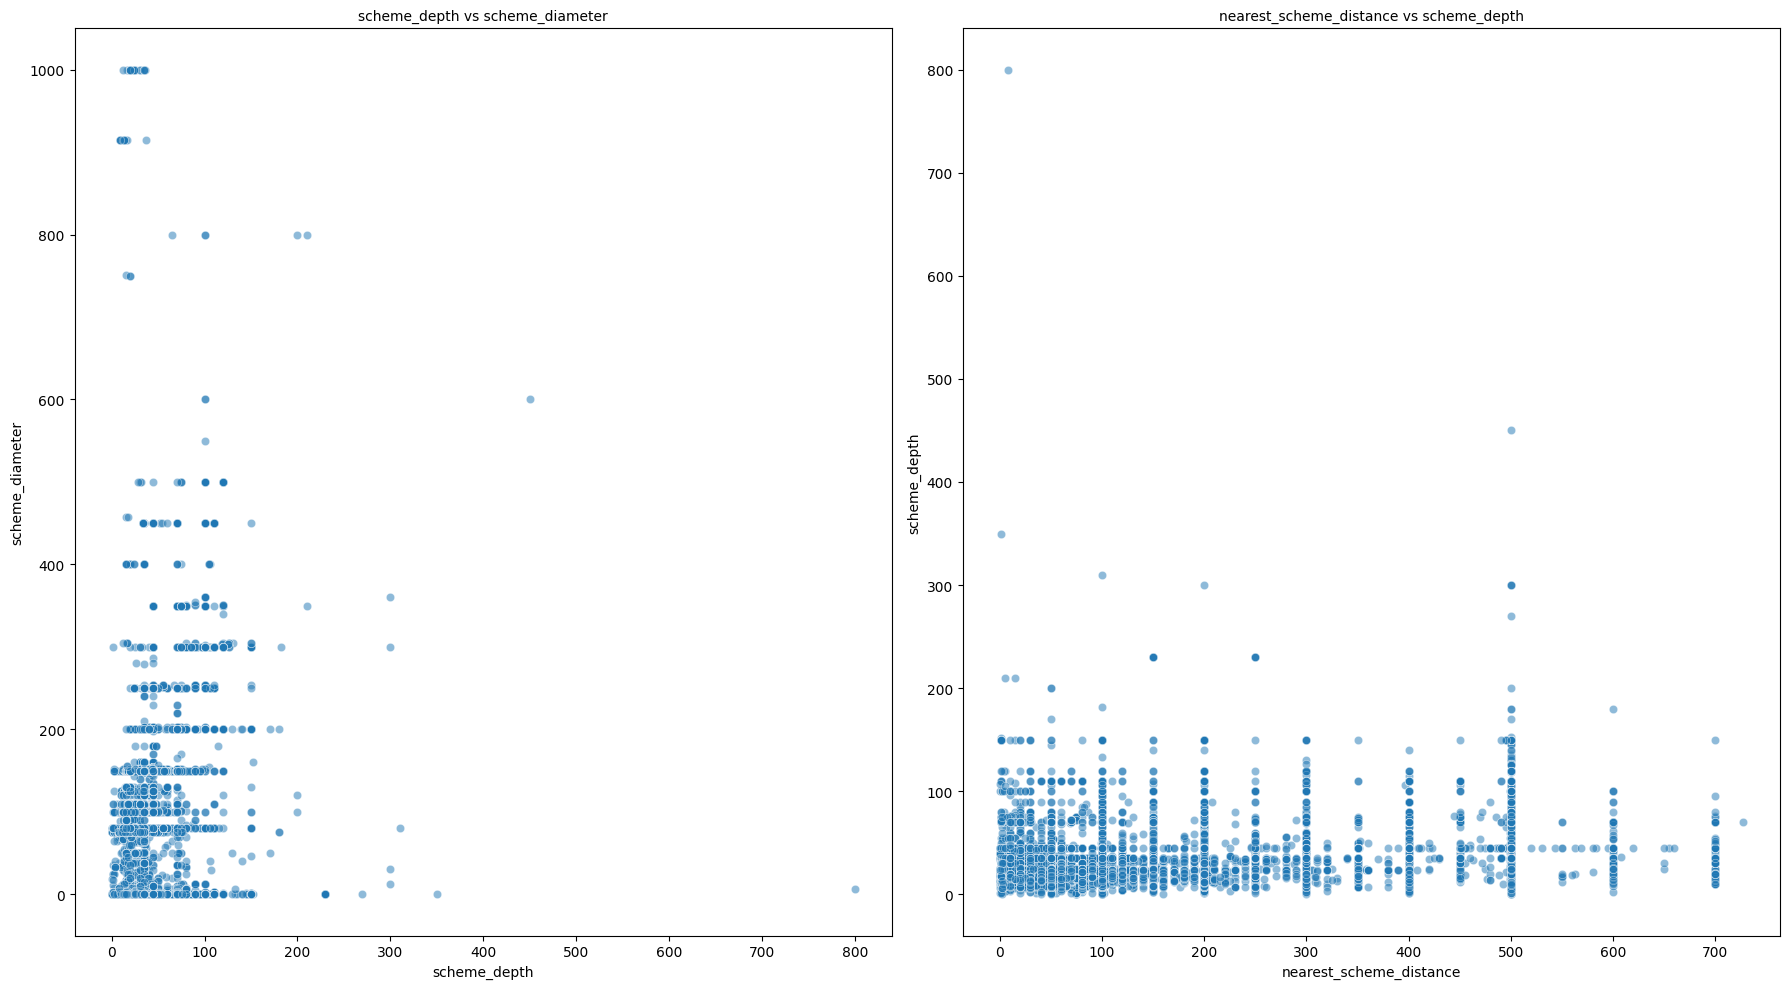

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select meaningful numerical feature pairs
feature_pairs = [
    ("scheme_depth", "scheme_diameter"),
    ("nearest_scheme_distance", "scheme_depth")
]

# Create scatterplots
fig, axes = plt.subplots(1, 2, figsize=(18, 10))
axes = axes.flatten()

for ax, (x_col, y_col) in zip(axes, feature_pairs):

    sns.scatterplot(
        data=df,
        x=x_col,
        y=y_col,
        ax=ax,
        alpha=0.5
    )

    ax.set_title(f"{x_col} vs {y_col}", fontsize=10)

plt.tight_layout()
plt.show()

## 2.2 Proximity-Based Methods

### Local Outlier Factor (LOF)

In [30]:
import pandas as pd
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

# Select meaningful numerical feature pairs
feature_pairs = [
    ("scheme_depth", "scheme_diameter"),
    ("nearest_scheme_distance", "scheme_depth")
]

# Store LOF results
lof_summary = []

for x_col, y_col in feature_pairs:

    # Select features and remove missing values
    X = df[[x_col, y_col]].dropna().copy()

    # Remove duplicate feature combinations
    X_unique = X.drop_duplicates()

    if len(X_unique) < 3:
        continue

    # Scale features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_unique)

    # Apply LOF
    lof = LocalOutlierFactor(
        n_neighbors=min(30, len(X_unique) - 1),
        contamination="auto",
        n_jobs=-1
    )

    predictions = lof.fit_predict(X_scaled)

    # Calculate outlier count
    outlier_count = (predictions == -1).sum()
    outlier_percentage = (outlier_count / len(X_unique)) * 100

    # Store summary
    lof_summary.append({
        "Feature Pair": f"{x_col} vs {y_col}",
        "Unique Combinations": len(X_unique),
        "Outlier Count": outlier_count,
        "Outlier Percentage": outlier_percentage
    })

# Display results
lof_summary = pd.DataFrame(lof_summary)

display(
    lof_summary.sort_values(
        by="Outlier Count",
        ascending=False
    ).round(2)
)

,Feature Pair,Unique Combinations,Outlier Count,Outlier Percentage
0,scheme_depth vs scheme_diameter,2410,276,11.45
1,nearest_scheme_distance vs scheme_depth,2882,55,1.91


#### Treatement

##### Workign on scheme_depth

In [31]:
# Compare scheme depth across well types
well_depth_summary = (
    df.groupby('well_type', dropna=False)
    .agg(
        Records=('scheme_depth', 'count'),
        Minimum=('scheme_depth', 'min'),
        Q1=('scheme_depth', lambda x: x.quantile(0.25)),
        Median=('scheme_depth', 'median'),
        Q3=('scheme_depth', lambda x: x.quantile(0.75)),
        Maximum=('scheme_depth', 'max'),
        Mean=('scheme_depth', 'mean')
    )
    .round(2)
)

display(well_depth_summary)

,Records,Minimum,Q1,Median,Q3,Maximum,Mean
well_type,,,,,,,
Dugwell: Dug well Kutcha,224,0.10,7.0,10.0,30.00,70.0,17.87
Dugwell: Dug well Pucca,456,1.00,9.0,13.0,26.25,120.0,22.34
Dugwell: Dug-cum-bore well,61,5.00,30.0,39.6,59.00,170.0,51.55
Dugwell: Others,23,10.00,18.5,45.0,70.00,110.0,50.94
Tubewell: Artesian Well,19,4.00,16.5,32.0,35.00,45.0,25.87
Tubewell: Deep Tube well,1236,70.10,75.0,95.0,110.00,800.0,98.64
Tubewell: Medium Tube well,6743,35.05,45.0,45.0,45.00,70.0,48.11
Tubewell: Shallow Tube well,46496,0.03,17.0,20.0,25.00,45.0,21.89


## 2.3 Clustering-Based Methods

### MiniBatchKMeans

In [32]:
import pandas as pd
import numpy as np
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import StandardScaler

# Select all numerical features
X = df[numeric_cols].copy()

# Scale numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply MiniBatchKMeans
kmeans = MiniBatchKMeans(
    n_clusters=5,
    random_state=42,
    batch_size=1024,
    n_init=3
)

labels = kmeans.fit_predict(X_scaled)

# Calculate distance from assigned cluster centres
distances = np.linalg.norm(
    X_scaled - kmeans.cluster_centers_[labels],
    axis=1
)

# Identify outliers using 95th percentile threshold
threshold = np.percentile(distances, 95)

# Calculate outlier count directly
outlier_mask = distances > threshold

outlier_count = outlier_mask.sum()
normal_count = (~outlier_mask).sum()
outlier_percentage = outlier_mask.mean() * 100

# Display summary
print("Distance Threshold:", round(threshold, 4))
print("Total Outliers:", outlier_count)
print("Total Normal:", normal_count)
print("Outlier Percentage:", round(outlier_percentage, 2), "%")

Distance Threshold: 4.0705
Total Outliers: 2763
Total Normal: 52495
Outlier Percentage: 5.0 %


## 2.4 Statistical Methods

### Mahalanobis Distance

In [33]:
import pandas as pd
import numpy as np
from scipy.stats import chi2

feature_pairs = [
    ("scheme_depth", "scheme_diameter"),
]

mahalanobis_summary = []

for x_col, y_col in feature_pairs:

    X = df[[x_col, y_col]].dropna()

    if len(X) < 3 or X.nunique().min() <= 1:
        continue

    mean = X.mean().values
    cov = np.cov(X.values, rowvar=False)
    inv_cov = np.linalg.pinv(cov)

    diff = X.values - mean
    distances = np.sum((diff @ inv_cov) * diff, axis=1)

    threshold = chi2.ppf(0.99, df=2)
    outliers = distances > threshold


    # Store summary
    mahalanobis_summary.append({
        "Feature Pair": f"{x_col} vs {y_col}",
        "Outlier Count": outliers.sum(),
        "Outlier Percentage": outliers.mean() * 100
    })

mahalanobis_summary = pd.DataFrame(mahalanobis_summary)

display(mahalanobis_summary.sort_values(
    by="Outlier Count",
    ascending=False
))

,Feature Pair,Outlier Count,Outlier Percentage
0,scheme_depth vs scheme_diameter,1811,3.277354


# 3. Multivariate Outlier Detection

## 3.1 ML-Based Methods

### Isolation Forest

In [34]:
import pandas as pd
import numpy as np

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

# Select numerical features, excluding target and coordinates
features = [
    col for col in numeric_cols
    if col not in [
        'construction_cost',
        'latitude',
        'longitude'
    ]
]

# Prepare data
X = df[features].copy()

X = X.replace([np.inf, -np.inf], np.nan)

valid_mask = X.notna().all(axis=1)
X_clean = X.loc[valid_mask]

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clean)

# Apply Isolation Forest
iso_forest = IsolationForest(
    n_estimators=100,
    contamination='auto',
    random_state=42,
    n_jobs=-1
)

predictions = iso_forest.fit_predict(X_scaled)

# Extract outliers
outliers = df.loc[X_clean.index[predictions == -1]].copy()

# Summary
print("Total Records:", len(X_clean))
print("Total Outliers:", len(outliers))
print("Outlier Percentage:",
      round(len(outliers) / len(X_clean) * 100, 2), "%")

# Display selected columns
display(
    outliers[
        features + [
            'construction_cost',
            'well_type',
            'district_name'
        ]
    ].head(30)
)

Total Records: 55258
Total Outliers: 5126
Outlier Percentage: 9.28 %


,total_owners_holding,scheme_depth,scheme_diameter,nearest_scheme_distance,horse_power_of_lifting_device,culturable_command_area,construction_cost,well_type,district_name
47,0.0,110.0,0.45,500.0,20.0,0.00,9000000.0,Tubewell: Deep Tube well,Kamrup
51,0.0,45.0,0.25,200.0,15.0,2.53,2683800.0,Tubewell: Medium Tube well,Majuli
55,0.0,110.0,0.45,100.0,20.0,0.00,9000000.0,Tubewell: Deep Tube well,Kamrup
73,0.0,75.0,0.40,100.0,2.0,50.00,200000.0,Tubewell: Deep Tube well,Jorhat
74,0.0,75.0,0.40,100.0,2.0,50.00,200000.0,Tubewell: Deep Tube well,Jorhat
80,0.0,45.0,0.40,100.0,3.0,60.00,900000.0,Tubewell: Medium Tube well,Jorhat
135,0.0,45.0,0.40,100.0,3.0,60.00,900000.0,Tubewell: Medium Tube well,Jorhat
136,0.0,45.0,0.40,100.0,3.0,60.00,900000.0,Tubewell: Medium Tube well,Jorhat
137,0.0,45.0,0.40,100.0,3.0,50.00,900000.0,Tubewell: Medium Tube well,Jorhat
138,0.0,45.0,0.40,100.0,3.0,60.00,500000.0,Tubewell: Medium Tube well,Jorhat


In [35]:
# Check exact duplicate records
print("Duplicate records:", df.duplicated().sum())

# Remove exact duplicates
df = df.drop_duplicates().copy()

print("Records after removing duplicates:", len(df))

Duplicate records: 1807
Records after removing duplicates: 53451


### One-Class SVM

In [36]:
import pandas as pd
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

# Select all numerical features
X = df[numeric_cols].copy()

# Scale numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Initialize One-Class SVM
oc_svm_multi = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.05
)

# Train the model and predict outliers
predictions = oc_svm_multi.fit_predict(X_scaled)

# Display summary
print("Total Outliers:", (predictions == -1).sum())
print("Total Normal:", (predictions == 1).sum())

print(
    "Outlier Percentage:",
    round((predictions == -1).mean() * 100, 2), "%"
)

Total Outliers: 2673
Total Normal: 50778
Outlier Percentage: 5.0 %


### Autoencoders

In [38]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping

# ==========================================
# 1. SELECT NUMERICAL FEATURES
# ==========================================

# Exclude target and geographical coordinates
features = [
    col for col in numeric_cols
    if col not in [
        'construction_cost',
        'latitude',
        'longitude'
    ]
]

X = df[features].copy()

# Handle infinite values
X = X.replace([np.inf, -np.inf], np.nan)

# Keep records with complete numerical features
valid_mask = X.notna().all(axis=1)
X_clean = X.loc[valid_mask]

print("Total Records:", len(df))
print("Records Used:", len(X_clean))
print("Records Excluded:", len(df) - len(X_clean))


# ==========================================
# 2. SCALE NUMERICAL FEATURES
# ==========================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_clean)


# ==========================================
# 3. DEFINE AUTOENCODER ARCHITECTURE
# ==========================================

input_dim = X_scaled.shape[1]

input_layer = Input(shape=(input_dim,))

# Encoder
encoded = Dense(16, activation="relu")(input_layer)
encoded = Dense(8, activation="relu")(encoded)

# Decoder
decoded = Dense(16, activation="relu")(encoded)
decoded = Dense(input_dim, activation="linear")(decoded)

autoencoder = Model(input_layer, decoded)


# ==========================================
# 4. COMPILE MODEL
# ==========================================

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)


# ==========================================
# 5. TRAIN AUTOENCODER
# ==========================================

early_stopping = EarlyStopping(
    monitor="loss",
    patience=5,
    restore_best_weights=True
)

history = autoencoder.fit(
    X_scaled,
    X_scaled,
    epochs=50,
    batch_size=256,
    shuffle=True,
    callbacks=[early_stopping],
    verbose=1
)


# ==========================================
# 6. RECONSTRUCT INPUT DATA
# ==========================================

reconstructed = autoencoder.predict(
    X_scaled,
    verbose=0
)


# ==========================================
# 7. CALCULATE RECONSTRUCTION ERROR
# ==========================================

reconstruction_error = np.mean(
    np.square(X_scaled - reconstructed),
    axis=1
)


# ==========================================
# 8. IDENTIFY OUTLIERS
# ==========================================

threshold = np.percentile(
    reconstruction_error,
    95
)

# Initialize column
df["Autoencoder_Outlier"] = 0

# Assign reconstruction errors to valid records
df.loc[X_clean.index, "Reconstruction_Error"] = reconstruction_error

# Flag outliers
df.loc[
    X_clean.index[reconstruction_error > threshold],
    "Autoencoder_Outlier"
] = 1


# ==========================================
# 9. DISPLAY OUTLIER SUMMARY
# ==========================================

total_outliers = df["Autoencoder_Outlier"].sum()
total_normal = (df["Autoencoder_Outlier"] == 0).sum()

print("\n========== AUTOENCODER RESULTS ==========")

print("Reconstruction Error Threshold:", threshold)
print("Total Records:", len(df))
print("Total Outliers:", total_outliers)
print("Total Normal:", total_normal)

print(
    "Outlier Percentage:",
    round(total_outliers / len(df) * 100, 2),
    "%"
)


# ==========================================
# 10. EXTRACT OUTLIER RECORDS
# ==========================================

autoencoder_outliers = df[
    df["Autoencoder_Outlier"] == 1
].copy()

print("\nOutlier Records:")
display(
    autoencoder_outliers[
        features + [
            "construction_cost",
            "well_type",
            "district_name",
            "Reconstruction_Error"
        ]
    ].head(30)
)


# ==========================================
# 11. OUTLIER DISTRIBUTION
# ==========================================

print("\nOutliers by District:")

display(
    autoencoder_outliers["district_name"]
    .value_counts()
    .head(20)
)

print("\nOutliers by Well Type:")

display(
    autoencoder_outliers["well_type"]
    .value_counts()
)

Total Records: 53451
Records Used: 53451
Records Excluded: 0
Epoch 1/50
209/209 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.6432
Epoch 2/50
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2036
Epoch 3/50
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1074
Epoch 4/50
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0663
Epoch 5/50
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0346
Epoch 6/50
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0162
Epoch 7/50
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0094
Epoch 8/50
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0068
Epoch 9/50
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0044
Epoch 10/50
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0034
Epoch 11/50
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0030
Epoch 12/50
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0046
Epoch 13/50
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0070
Epoch 14/50
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0

,total_owners_holding,scheme_depth,scheme_diameter,nearest_scheme_distance,horse_power_of_lifting_device,culturable_command_area,construction_cost,well_type,district_name,Reconstruction_Error
2,0.0,69.0,150.00,69.0,3.0,4.00,450000.0,Tubewell: Medium Tube well,Goalpara,0.000993
47,0.0,110.0,0.45,500.0,20.0,0.00,9000000.0,Tubewell: Deep Tube well,Kamrup,0.008647
51,0.0,45.0,0.25,200.0,15.0,2.53,2683800.0,Tubewell: Medium Tube well,Majuli,0.001726
55,0.0,110.0,0.45,100.0,20.0,0.00,9000000.0,Tubewell: Deep Tube well,Kamrup,0.008234
73,0.0,75.0,0.40,100.0,2.0,50.00,200000.0,Tubewell: Deep Tube well,Jorhat,0.005520
74,0.0,75.0,0.40,100.0,2.0,50.00,200000.0,Tubewell: Deep Tube well,Jorhat,0.005520
80,0.0,45.0,0.40,100.0,3.0,60.00,900000.0,Tubewell: Medium Tube well,Jorhat,0.008230
128,2.0,2.0,8.00,80.0,5.0,2.00,6000.0,Tubewell: Shallow Tube well,Dhubri,0.001194
135,0.0,45.0,0.40,100.0,3.0,60.00,900000.0,Tubewell: Medium Tube well,Jorhat,0.008230
136,0.0,45.0,0.40,100.0,3.0,60.00,900000.0,Tubewell: Medium Tube well,Jorhat,0.008230



Outliers by District:


district_name
Karbi Anglong              375
Jorhat                     223
Kamrup                     183
Darrang                    171
Dhubri                     149
Goalpara                   137
Biswanath                  120
Golaghat                   113
Hojai                      106
Barpeta                     98
Sonitpur                    88
Nagaon                      84
Dibrugarh                   78
Tinsukia                    69
Bongaigaon                  68
Nalbari                     63
Kokrajhar                   58
Marigaon                    51
Cachar                      49
South Salmara Mancachar     44
Name: count, dtype: int64


Outliers by Well Type:


well_type
Tubewell: Deep Tube well       1078
Tubewell: Shallow Tube well     746
Tubewell: Medium Tube well      447
Dugwell: Dug well Pucca         249
Dugwell: Dug well Kutcha        127
Dugwell: Dug-cum-bore well       17
Dugwell: Others                   7
Tubewell: Artesian Well           2
Name: count, dtype: int64

## 3.2 Proximity-Based Methods

### Local Outlier Factor (LOF)


In [39]:
import pandas as pd
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

# Select all numerical features
X = df[numeric_cols].copy()

# Scale numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Initialize LOF (proximity-based detection)
lof_multi = LocalOutlierFactor(
    n_neighbors=20,
    contamination="auto",
    n_jobs=-1
)

# Detect outliers
predictions = lof_multi.fit_predict(X_scaled)

# Display summary
print("Total Outliers:", (predictions == -1).sum())
print("Total Normal:", (predictions == 1).sum())

print(
    "Outlier Percentage:",
    round((predictions == -1).mean() * 100, 2), "%"
)

Total Outliers: 9719
Total Normal: 43732
Outlier Percentage: 18.18 %


## 3.3 Clustering-Based Methods

### Density-Based DBSCAN

In [40]:
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

# Select all numerical features
X = df[numeric_cols].copy()

# Scale numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Initialize DBSCAN
dbscan_multi = DBSCAN(
    eps=0.5,
    min_samples=5,
    n_jobs=-1
)

# Apply DBSCAN
labels = dbscan_multi.fit_predict(X_scaled)

# Count clusters and outliers
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_outliers = (labels == -1).sum()

# Display summary
print("Number of Clusters:", n_clusters)
print("Total Outliers:", n_outliers)
print("Total Normal:", len(labels) - n_outliers)

print(
    "Outlier Percentage:",
    round(n_outliers / len(labels) * 100, 2),
    "%"
)

Number of Clusters: 344
Total Outliers: 4574
Total Normal: 48877
Outlier Percentage: 8.56 %


### Density-Based KMeans

In [57]:
import pandas as pd
import numpy as np

from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import StandardScaler

# =====================================
# 1. SELECT NUMERICAL FEATURES
# =====================================

features = [
    col for col in numeric_cols
    if col not in [
        'construction_cost',
        'latitude',
        'longitude'
    ]
]

X = df[features].copy()

# Handle missing and infinite values
X = X.replace([np.inf, -np.inf], np.nan)

valid_mask = X.notna().all(axis=1)
X_clean = X.loc[valid_mask]


# =====================================
# 2. SCALE FEATURES
# =====================================

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clean)


# =====================================
# 3. APPLY MINIBATCH K-MEANS
# =====================================

kmeans = MiniBatchKMeans(
    n_clusters=5,
    random_state=42,
    n_init=10,
    batch_size=1024
)

labels = kmeans.fit_predict(X_scaled)


# =====================================
# 4. CALCULATE CENTROID DISTANCES
# =====================================

distances = np.linalg.norm(
    X_scaled - kmeans.cluster_centers_[labels],
    axis=1
)


# =====================================
# 5. IDENTIFY OUTLIERS
# =====================================

threshold = np.percentile(distances, 95)

outlier_mask = distances > threshold

outlier_indices = X_clean.index[outlier_mask]

# Extract outliers without modifying df
kmeans_outliers = df.loc[outlier_indices].copy()


# =====================================
# 6. DISPLAY SUMMARY
# =====================================

total_outliers = len(kmeans_outliers)
total_normal = len(df) - total_outliers

print("Distance Threshold:", threshold)
print("Total Records:", len(df))
print("Records Used:", len(X_clean))
print("Total Outliers:", total_outliers)
print("Total Normal:", total_normal)

print(
    "Outlier Percentage:",
    round(total_outliers / len(df) * 100, 2),
    "%"
)


# =====================================
# 7. DISPLAY OUTLIER RECORDS
# =====================================

display(kmeans_outliers.head(30))


# =====================================
# 8. VERIFY ORIGINAL DATAFRAME
# =====================================

print("\nOriginal DataFrame Columns:", len(df.columns))
print("Outlier DataFrame Columns:", len(kmeans_outliers.columns))

# Remove columns created by previous K-Means detection
df.drop(
    columns=['KMeans_Outlier', 'KMeans_Distance'],
    errors='ignore',
    inplace=True
)

# Verify
print("Total Columns:", len(df.columns))
print(df.columns.tolist())

df.info()

Distance Threshold: 1.5674331825881582
Total Records: 57130
Records Used: 57130
Total Outliers: 2857
Total Normal: 54273
Outlier Percentage: 5.0 %


,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,ownership,total_owners_holding,social_status,...,located_in_command_area,only_recharge_ground_water,culturable_command_area,under_utilised_selection,drinking_water_purpose,captured_in_previous_census,well_type,finance_source,KMeans_Outlier,KMeans_Distance
2,Goalpara,Kuchdhowa,Patiarpara Pt-I,25.971319,90.917621,1,Tube well,Govt. Owned,0.0,Not applicable,...,No,No,4.0,Unknown,No,Yes,Tubewell: Medium Tube well,Government fund,1,2.716519
47,Kamrup,Bihdia -Jajikona,Muktapur,26.439953,91.722332,1,Tube well,Govt. Owned,0.0,Not applicable,...,No,No,0.0,No,Yes,No,Tubewell: Deep Tube well,Government fund,1,4.194196
55,Kamrup,Bihdia -Jajikona,Loch,26.432798,91.734537,1,Tube well,Govt. Owned,0.0,Not applicable,...,No,No,0.0,No,Yes,No,Tubewell: Deep Tube well,Government fund,1,4.656248
56,Cachar,Silchar,Ambicapur Pt II,24.815678,92.764168,7,Tube well,Owned by Group of farmers,0.0,Not applicable,...,No,No,4.0,No,No,No,Tubewell: Medium Tube well,Owned by Group of farmers,0,1.116454
73,Jorhat,Jorhat East,Gharphalia Gaon,26.719807,94.463250,1,Tube well,Owned by Group of farmers,0.0,Not applicable,...,No,No,50.0,No,No,No,Tubewell: Deep Tube well,Owned by Group of farmers,1,6.615963
74,Jorhat,Jorhat East,Gharphalia Gaon,26.719773,94.463252,2,Tube well,Owned by Group of farmers,0.0,Not applicable,...,No,No,50.0,No,Yes,No,Tubewell: Deep Tube well,Owned by Group of farmers,1,6.615963
80,Jorhat,Kaliapani,Tulashijonia Pohumora Gaon,26.865845,94.458647,5,Tube well,Govt. Owned,0.0,Not applicable,...,No,No,60.0,No,No,No,Tubewell: Medium Tube well,Government fund,1,7.631743
99,Cachar,Silchar,Bajantipur Pt II,24.810315,92.746877,6,Tube well,Owned by Group of farmers,0.0,Not applicable,...,No,No,4.0,Yes,No,No,Tubewell: Medium Tube well,Owned by Group of farmers,0,1.116454
135,Jorhat,Kaliapani,Jogduarhabi Gaon,26.863587,94.431562,2,Tube well,Govt. Owned,0.0,Not applicable,...,No,No,60.0,No,No,No,Tubewell: Medium Tube well,Government fund,1,7.631743
136,Jorhat,Kaliapani,Jogduarhabi Gaon,26.864430,94.430411,3,Tube well,Govt. Owned,0.0,Not applicable,...,No,No,60.0,No,No,No,Tubewell: Medium Tube well,Government fund,1,7.631743



Original DataFrame Columns: 31
Outlier DataFrame Columns: 31
Total Columns: 29
['district_name', 'block_tehsil_name', 'village_name', 'latitude', 'longitude', 's_no_of_scheme', 'scheme_type', 'ownership', 'total_owners_holding', 'social_status', 'gender', 'commissioning_year', 'scheme_depth', 'scheme_diameter', 'nearest_scheme_distance', 'construction_cost', 'scheme_status', 'water_distribution_method', 'lifting_device_type', 'energy_source', 'horse_power_of_lifting_device', 'located_in_command_area', 'only_recharge_ground_water', 'culturable_command_area', 'under_utilised_selection', 'drinking_water_purpose', 'captured_in_previous_census', 'well_type', 'finance_source']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57130 entries, 0 to 57129
Data columns (total 29 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   district_name                  57130 non-null  object 
 1   block_tehsil_name        

# Save Dataset

In [59]:
print(df.shape)

(57130, 29)


In [60]:
df.to_csv("./data/04_Outlar_Detection.csv", index=False)